# `collapse-in-pipeline.ipynb`

Connor Shrader / July 22, 2025

The purpose of this file is to experiment with collapsing barcodes starting from the `all_data.csv` file, for eventual inclusion into the main pipeline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # for heatmaps
import Levenshtein # for distance computation
from sklearn.cluster import DBSCAN # for clustering
from tqdm import trange # for loop progress bar
import BarcodeRemap as br
import pandas as pd
import networkx as nx

In [2]:
# Append the file that contain's Drew's wonderful sequence conversion code.
import sys, os

sister_path = '../fastq-data'
sys.path.append(sister_path)

import BarcodeRemap as br

In [3]:
# Load in all the data and save everything in fish 5, sample 6, replicate 1 to the variable `fish5`.
all_data = pd.read_csv('../experiments/07.29.2025_09.33_AM/pre-filtered-data.csv')

fish5 = all_data[all_data['fish'] == 'fish5'].copy()
print(f'There are {len(fish5)} entries in the dataset')
fish5.head()

There are 514 entries in the dataset


,barcode,fish,sample,replicate,file,reads,proportion
924,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,fish5,1,1,fish5_s1_rep1,6357,0.574514
925,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,fish5,1,1,fish5_s1_rep1,1331,0.120289
926,NONE_NONE_NONE_NONE_108D+142_108D+142_108D+142...,fish5,1,1,fish5_s1_rep1,783,0.070764
927,3D+37_NONE_NONE_NONE_NONE_89D+168_89D+168_89D+...,fish5,1,1,fish5_s1_rep1,537,0.048531
928,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,fish5,1,1,fish5_s1_rep1,380,0.034343


In [4]:
# Compute the sequences from barcodes.
reference_seq = br.BarcodeRemap().zebrafish_reference_sequence
fish5['sequence'] = fish5['barcode'].apply(lambda x: br.get_sequence(x, reference_seq).upper())

In [5]:
df_grouped = fish5.groupby(['sequence', 'barcode'], as_index = False)['reads'].sum().sort_values('reads', ascending = False).reset_index(drop=True)
seqs = np.array(df_grouped['sequence'])
n_seqs = len(seqs)

print(f'There are {n_seqs} unique sequences in this data.')

There are 43 unique sequences in this data.


In [7]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(i, n_seqs):  # Only upper triangle
        d = Levenshtein.distance(seqs[i], seqs[j])
        distances[i, j] = d
        distances[j, i] = d  # Symmetric

100%|█████████████████████████████████████████████| 43/43 [00:00<00:00, 6845.11it/s]


In [8]:
df_grouped.head()

,sequence,barcode,reads
0,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTC...,2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NO...,365910
1,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,291240
2,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,239355
3,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACGATGGAG...,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,185163
4,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGGAGTCGAGA...,87D+36_87D+36_87D+36_87D+36_NONE_1D+172_NONE_N...,18368


In [9]:
d = distances.copy()
np.fill_diagonal(d, np.inf) # don't connect nodes with themselves
G = nx.from_numpy_array(d <= 1)

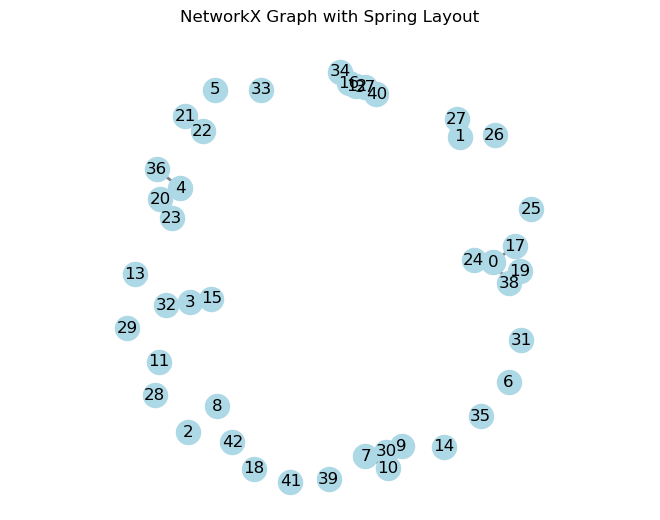

In [10]:
pos = nx.spring_layout(G, seed=42, k=0.25, threshold = 1e-8)  # You can adjust seed or add k=0.5–1.5 to control spacing

# Draw the graph with styling
nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    edge_color='gray',
    node_size=300,
    width=2  # Thicker edges
)

plt.title("NetworkX Graph with Spring Layout")
plt.axis("equal")  # Optional: keeps proportions neat
plt.show()

In [11]:
component_map = {}
for idx, component in enumerate(nx.connected_components(G)):
    for node in component:
        component_map[node] = idx

sorted_values = np.array([value for key, value in sorted(component_map.items())])
df_grouped['component'] = sorted_values
sorted_values

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  7,  7,  9, 10, 11, 12,  3, 13,
        0, 14, 15,  4, 16, 16,  4,  0, 17, 18,  1, 19, 20, 21, 22,  3, 23,
       24, 25,  4, 24,  0, 26, 13, 27, 28])

In [12]:
fish5_collapsed = fish5.copy()

In [13]:
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

In [14]:
components = list(nx.connected_components(G))
for i, c in enumerate(nx.connected_components(G)):
    # c = np.array(list(component))
    barcodes = df_grouped['barcode'][list(c)]
    component = df_grouped[df_grouped['barcode'].isin(barcodes)]
    # print(component)
    idx = component.index
    print(f"Component {i}: indices {list(idx)}")
    # print(c)
    d = distances[np.ix_(idx, idx)]
    mean_distance = np.mean(d, axis = 0)
    idx_min_distance = idx[np.argmin(mean_distance)]
    
    triu = np.triu(d)
    print(f'Max distance between barcodes: {int(np.max(triu))}.')
    for j, row in component.iterrows():
        # print(idx_min_distance)
        if j == idx_min_distance:
            print(f"{row['reads']:>6}\t*{row['barcode']}.")
        else:
            print(f"{row['reads']:>6}\t {row['barcode']}.")

    if unedited_barcode in component['barcode']:
        winner_barcode = unedited_barcode
    else:
        winner_barcode = component.iloc[0]['barcode']
        
    fish5_collapsed.loc[fish5_collapsed['barcode'].isin(barcodes), 'barcode'] = winner_barcode

    print('')

Component 0: indices [0, 17, 24, 38]
Max distance between barcodes: 2.
365910	*2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_NONE_NONE.
  3656	 3D+35_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_NONE_NONE.
   931	 2D+36_81D+61_81D+61_81D+61_81D+61_1D+172_NONE_NONE_NONE_NONE.
    95	 2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_1D+254_NONE.

Component 1: indices [1, 27]
Max distance between barcodes: 1.
291240	*NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE.
   335	 1D+37_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE.

Component 2: indices [2]
Max distance between barcodes: 0.
239355	*NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+167_87D+167_NONE.

Component 3: indices [3, 15, 32]
Max distance between barcodes: 2.
185163	*54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_NONE_NONE.
  5482	 54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_1D+254_NONE.
   183	 54D+36_54D+36_54D+36_NONE_1I+145+A_NONE_NONE_NONE_NONE_NONE.

Component 4: indices [4, 20, 23, 36]
Max distance between barcodes: 

In [15]:
# Combine rows that share the same (reassigned) barcode
fish5_collapsed = (
    fish5_collapsed.groupby(['barcode', 'fish', 'sample', 'replicate', 'file'], as_index=False)
      .agg({'reads': 'sum', 'proportion': 'sum'})
)

In [17]:
print(f'There are {len(fish5_collapsed["barcode"].unique())} unique sequences in this data.')

There are 29 unique sequences in this data.


In [38]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 3

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [39]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 29 items
Cluster 0: 4 items
Cluster 1: 3 items
Cluster 2: 4 items
Cluster 3: 3 items


In [40]:
for label in unique_labels[1:]:
    print(f'Cluster {label}')
    for i, row in df_grouped[labels == label].iterrows():
        print(f"{row['reads']:>6}\t {row['barcode']}.")

Cluster 0
365910	 2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_NONE_NONE.
  3656	 3D+35_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_NONE_NONE.
   931	 2D+36_81D+61_81D+61_81D+61_81D+61_1D+172_NONE_NONE_NONE_NONE.
    95	 2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NONE_1D+254_NONE.
Cluster 1
185163	 54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_NONE_NONE.
  5482	 54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_1D+254_NONE.
   183	 54D+36_54D+36_54D+36_NONE_1I+145+A_NONE_NONE_NONE_NONE_NONE.
Cluster 2
 18368	 87D+36_87D+36_87D+36_87D+36_NONE_1D+172_NONE_NONE_NONE_NONE.
  2029	 87D+36_87D+36_87D+36_87D+36_NONE_NONE_NONE_NONE_NONE_NONE.
   992	 87D+35_87D+35_87D+35_87D+35_NONE_NONE_NONE_NONE_NONE_NONE.
   113	 87D+36_87D+36_87D+36_87D+36_1D+146_1D+172_NONE_NONE_NONE_NONE.
Cluster 3
 12690	 NONE_NONE_NONE_NONE_1D+146_81D+170_81D+170_81D+170_81D+170_NONE.
 10521	 NONE_NONE_NONE_NONE_NONE_82D+172_82D+172_82D+172_82D+172_NONE.
  9030	 NONE_NONE_NONE_NONE_NONE_81D+170_81D+170_81D+170_81D+170_

## Collapse every fish!

In [41]:
# Load in all the data and save everything in fish 5, sample 6, replicate 1 to the variable `fish5`.
all_data = pd.read_csv('../experiments/07.29.2025_09.33_AM/pre-filtered-data.csv')

In [42]:
reference_seq = br.BarcodeRemap().zebrafish_reference_sequence
all_data['sequence'] = all_data['barcode'].apply(lambda x: br.get_sequence(x, reference_seq).upper())

In [43]:
grouped_data = all_data.groupby(['fish', 'sequence', 'barcode'], as_index = False)['reads'].sum().sort_values('reads', ascending = False).reset_index(drop=True)
unique_seqs = np.array(grouped_data['sequence'])
n_seqs = len(unique_seqs)

print(f'There are {n_seqs} unique sequences in this data.')

There are 2381 unique sequences in this data.


In [44]:
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

In [45]:
collapsed_data = all_data.copy()

In [69]:
for fish in all_data['fish'].unique():
    grouped_fish_data = grouped_data[grouped_data['fish'] == fish].copy().reset_index(drop=True)

    unique_seqs = np.array(grouped_fish_data['sequence'])
    n_seqs = len(unique_seqs)

    # print(f'There are {n_seqs} unique sequences in {fish}.')

    # Compute Levenshtein distance between every pair of reads.
    distances = np.zeros((n_seqs, n_seqs))
    for i in range(n_seqs):
        for j in range(i, n_seqs):  # Only upper triangle
            d = Levenshtein.distance(unique_seqs[i], unique_seqs[j])
            distances[i, j] = d
            distances[j, i] = d  # Symmetric

    distances_inf_diag = distances.copy()
    np.fill_diagonal(distances_inf_diag, np.inf) # don't connect nodes with themselves
    G = nx.from_numpy_array(distances_inf_diag <= 1)

    components = list(nx.connected_components(G))
    for i, component in enumerate(components):
        barcodes = grouped_fish_data['barcode'][list(component)]
        component_data = grouped_fish_data[grouped_fish_data['barcode'].isin(barcodes)]
        
        idx = component_data.index
        # print(f"Component {i}: indices {list(idx)}")
        
        d = distances[np.ix_(idx, idx)]
        mean_distance = np.mean(d, axis = 0)
        idx_min_distance = np.argmin(mean_distance)
        
        triu = np.triu(d)
        # print(f'Max distance between barcodes: {int(np.max(triu))}. Max distance to center: {int(np.max(d[idx_min_distance, :]))}.')
        # for j, row in component_data.iterrows():
        #     if j == idx[idx_min_distance]:
        #         print(f"{row['reads']:>6}\t*{row['barcode']}.")
        #     else:
        #         print(f"{row['reads']:>6}\t {row['barcode']}.")
    
        if unedited_barcode in component_data['barcode']:
            winner_barcode = unedited_barcode
        else:
            winner_barcode = component_data.iloc[0]['barcode']
            
        collapsed_data.loc[(collapsed_data['fish'] == fish) & (collapsed_data['barcode'].isin(barcodes)), 'barcode'] = winner_barcode
    
        # print('')

In [109]:
def compute_levenshtein_matrix(sequences):
    """
    This function computes the pairwise distances between an array
    of DNA sequences.

    Input: `sequences`: An array of DNA sequences (of length n).
    
    Output: `D`: An (n x n) matrix where D[i, j] is the Levenshtein
                 distance between sequence i and sequence j.
    """
    n = len(sequences)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            d = Levenshtein.distance(sequences[i], sequences[j])
            D[i, j] = D[j, i] = d
    return D

def find_connected_components(D, threshold=1):
    d_inf = D.copy()
    np.fill_diagonal(d_inf, np.inf)
    G = nx.from_numpy_array(d_inf <= threshold)
    return list(nx.connected_components(G))

def summarize_component(i, component_data, distance_matrix, summary):
    idx = component_data.index
    local_distances = distance_matrix[np.ix_(idx, idx)]
    avg = np.mean(local_distances, axis=0)
    center_idx = np.argmin(avg)

    max_pairwise = int(np.max(np.triu(local_distances)))
    max_to_center = int(np.max(local_distances[center_idx, :]))

    summary.write(f"Component {i}: indices {list(idx)}\n")
    summary.write(f"Max distance between barcodes: {max_pairwise}. Max distance to center: {max_to_center}\n")
    
    for j, row in component_data.iterrows():
        marker = '*' if j == idx[center_idx] else ' '
        summary.write(f"{row['reads']:>6}\t{marker}{row['barcode']}.\n")

def resolve_winner_barcode(component_data, unedited_barcode):
    return unedited_barcode if unedited_barcode in component_data['barcode'].values else component_data.iloc[0]['barcode']

In [108]:
for fish in all_data['fish'].unique():
    summary = open(f'./clustering/{fish}.txt', 'w')
    
    fish_data = grouped_data.query("fish == @fish").reset_index(drop=True)
    sequences = np.array(fish_data['sequence'])

    summary.write(f"There are {len(sequences)} unique sequences in {fish}.\n")

    D = compute_levenshtein_matrix(sequences)
    components = find_connected_components(D)

    for i, comp in enumerate(components):
        barcodes = fish_data['barcode'].iloc[list(comp)]
        comp_data = fish_data[fish_data['barcode'].isin(barcodes)]
        
        summarize_component(i, comp_data, D, summary)
        winner = resolve_winner_barcode(comp_data, unedited_barcode)

        collapsed_data.loc[
            (collapsed_data['fish'] == fish) & 
            (collapsed_data['barcode'].isin(barcodes)), 'barcode'
        ] = winner
        
        summary.write('\n')

    summary.close() 

In [105]:
collapsed_data['sequence'] = collapsed_data['barcode'].apply(lambda x: br.get_sequence(x, reference_seq).upper())
seqs = collapsed_data.query("fish == 'fish8'")['sequence'].unique()
d = compute_levenshtein_matrix(seqs)
np.fill_diagonal(d, np.inf)
# np.where(d == 1)
np.min(d)

np.float64(2.0)